In [1]:
# Fitrya Irfan_202431073
# Langkah 1 - Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# Fitrya Irfan_202431073
# Langkah 2 - Membaca dataset
# Dataset : Pima Indians Diabetes Database (Kaggle: uciml)
# Link    : https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database
df = pd.read_csv('diabetes.csv')
print('Jumlah baris x kolom :', df.shape)
df.head()

Jumlah baris x kolom : (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Fitrya Irfan_202431073
# Langkah 2 (lanjutan) - info() dan describe()
df.info()
print()
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


In [4]:
# Fitrya Irfan_202431073
# Langkah 3 - Memeriksa target dan kelasnya
# Outcome = 0 -> tidak terdiagnosis diabetes ; Outcome = 1 -> terdiagnosis diabetes
jumlah = df['Outcome'].value_counts()
print(jumlah)
print()
print('Proporsi (%):')
print((df['Outcome'].value_counts(normalize=True) * 100).round(2))

Outcome
0    500
1    268
Name: count, dtype: int64

Proporsi (%):
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


In [5]:
# Fitrya Irfan_202431073
# Langkah 4 - Membersihkan dan menyiapkan data
# Tidak ada kolom ID dan tidak ada fitur kategori (semua numerik),
# sehingga tidak ada kolom yang dihapus maupun di-encode.
# Nilai 0 pada kolom berikut tidak masuk akal secara medis (mis. tekanan darah 0),
# jadi dianggap sebagai data hilang.
kolom_nol = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_bersih = df.copy()
df_bersih[kolom_nol] = df_bersih[kolom_nol].replace(0, np.nan)

print('Nilai hilang (hasil konversi 0 -> NaN):')
print(df_bersih.isna().sum())

# diisi dengan median tiap kolom
df_bersih[kolom_nol] = df_bersih[kolom_nol].fillna(df_bersih[kolom_nol].median())

print()
print('Nilai hilang setelah diisi median:', int(df_bersih.isna().sum().sum()))

Nilai hilang (hasil konversi 0 -> NaN):
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Nilai hilang setelah diisi median: 0


In [6]:
# Fitrya Irfan_202431073
# Langkah 5 - Memisahkan fitur (x) dan target (y), lalu membagi data latih dan uji
x = df_bersih.drop(columns=['Outcome'])
y = df_bersih['Outcome']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0, stratify=y)

print('Jumlah data latih :', x_train.shape[0])
print('Jumlah data uji   :', x_test.shape[0])
print('Proporsi kelas 1 pada data latih :', round(y_train.mean(), 4))
print('Proporsi kelas 1 pada data uji   :', round(y_test.mean(), 4))

Jumlah data latih : 576
Jumlah data uji   : 192
Proporsi kelas 1 pada data latih : 0.349
Proporsi kelas 1 pada data uji   : 0.349


In [7]:
# Fitrya Irfan_202431073
# Langkah 6 - Rentang fitur pada data latih
rentang = pd.DataFrame({'minimum': x_train.min(),
                        'maksimum': x_train.max()})
rentang['lebar_rentang'] = rentang['maksimum'] - rentang['minimum']
rentang = rentang.round(3)
print(rentang)
print()
print('Fitur dengan rentang terlebar:', rentang['lebar_rentang'].idxmax())

                          minimum  maksimum  lebar_rentang
Pregnancies                 0.000     17.00         17.000
Glucose                    44.000    199.00        155.000
BloodPressure              24.000    122.00         98.000
SkinThickness               7.000     99.00         92.000
Insulin                    14.000    846.00        832.000
BMI                        18.200     67.10         48.900
DiabetesPedigreeFunction    0.078      2.42          2.342
Age                        21.000     81.00         60.000

Fitur dengan rentang terlebar: Insulin


In [8]:
# Fitrya Irfan_202431073
# Langkah 7 - Pipeline StandardScaler + KNeighborsClassifier
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])
print(pipe)

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])


In [9]:
# Fitrya Irfan_202431073
# Langkah 8 - Memilih k dengan validasi silang (hanya memakai data latih)
param_grid = {'knn__n_neighbors': list(range(1, 20))}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy')
grid.fit(x_train, y_train)

print('k terbaik                    :', grid.best_params_['knn__n_neighbors'])
print('Skor validasi silang terbaik :', round(grid.best_score_, 4))

k terbaik                    : 17
Skor validasi silang terbaik : 0.7604


In [10]:
# Fitrya Irfan_202431073
# Langkah 9 - Model akhir dengan k terbaik, lalu prediksi data uji
model_akhir = grid.best_estimator_
y_pred = model_akhir.predict(x_test)

print('k yang dipakai      :', model_akhir.named_steps['knn'].n_neighbors)
print('20 prediksi pertama :', y_pred[:20])
print('20 label asli       :', y_test.values[:20])

k yang dipakai      : 17
20 prediksi pertama : [0 0 1 0 0 1 0 0 0 0 1 0 1 1 0 0 1 0 0 0]
20 label asli       : [0 0 0 0 0 0 1 1 0 1 0 1 1 1 0 0 0 0 0 0]


In [11]:
# Fitrya Irfan_202431073
# Langkah 10 - Evaluasi pada data uji
print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print()
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred))
print()
print('Classification report:')
nama_kelas = ['Tidak diabetes (0)', 'Diabetes (1)']
print(classification_report(y_test, y_pred, target_names=nama_kelas))

Accuracy : 0.7344

Confusion matrix:
[[106  19]
 [ 32  35]]

Classification report:
                    precision    recall  f1-score   support

Tidak diabetes (0)       0.77      0.85      0.81       125
      Diabetes (1)       0.65      0.52      0.58        67

          accuracy                           0.73       192
         macro avg       0.71      0.69      0.69       192
      weighted avg       0.73      0.73      0.73       192



In [12]:
# Fitrya Irfan_202431073
# Langkah 11 - Menguji satu data baru
data_baru = pd.DataFrame([{
    'Pregnancies': 3, 'Glucose': 130, 'BloodPressure': 72, 'SkinThickness': 28,
    'Insulin': 140, 'BMI': 32.5, 'DiabetesPedigreeFunction': 0.45, 'Age': 35
}])

# memeriksa apakah setiap fitur berada dalam rentang data latih
baris_baru = data_baru.iloc[0]
dalam_rentang = (baris_baru >= x_train.min()) & (baris_baru <= x_train.max())
print(dalam_rentang)
print('Semua fitur dalam rentang data latih:', bool(dalam_rentang.all()))
print()

prediksi = model_akhir.predict(data_baru)[0]
peluang = model_akhir.predict_proba(data_baru)[0]
print('Prediksi kelas :', prediksi, '(1 = diabetes, 0 = tidak diabetes)')
print('Peluang kelas 0 / 1 :', peluang.round(3))

Pregnancies                 True
Glucose                     True
BloodPressure               True
SkinThickness               True
Insulin                     True
BMI                         True
DiabetesPedigreeFunction    True
Age                         True
dtype: bool
Semua fitur dalam rentang data latih: True

Prediksi kelas : 0 (1 = diabetes, 0 = tidak diabetes)
Peluang kelas 0 / 1 : [0.529 0.471]


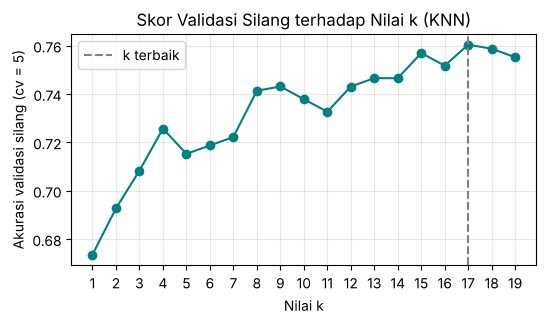

In [13]:
# Fitrya Irfan_202431073
# Langkah 12 - Grafik skor validasi silang terhadap nilai k
k_values = list(range(1, 20))
skor_cv = grid.cv_results_['mean_test_score']

plt.figure(figsize=(6, 3))
plt.plot(k_values, skor_cv, marker='o', color='teal')
k_terbaik = grid.best_params_['knn__n_neighbors']
plt.axvline(k_terbaik, linestyle='--', color='gray', label='k terbaik')
plt.title('Skor Validasi Silang terhadap Nilai k (KNN)')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi validasi silang (cv = 5)')
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.show()